# GyroSplat: the tables and figures of the main text

This notebook rebuilds the tables and figures of the main text from per-snapshot result rows and shows how to regenerate rows with this package. The appendix experiments have their own notebooks (`01` to `05`).

1. The codec on a synthetic snapshot (a CPU, a few seconds)
2. Table 1: every method at the same payload bytes, and the storage accounting of the recipes
3. Table 2: the ablation ladder (and the extended ladder of the appendix)
4. Figure 3: rate and distortion from 1000× to 100×
5. Table 3: the physics refinement on other codes, and the db4 wavelet
6. Figures of single fits
7. Rows regenerated with this package, dropped into the same tables
8. LaTeX

Two row files are read, and nothing here needs a GPU:

- `results/rows/gkw_rows.jsonl`: one fit per method and snapshot at the budgets of stored values, and the 23 rows of the ablation ladder (format in `gyrosplat/paper/rows.py`);
- `results/experiments/`: the fits behind the comparison at equal bytes (the fitting seeds, the Fourier and wavelet codes with the position of every kept coefficient counted) and the appendix experiments (format in `gyrosplat/paper/experiments.py`).

In [1]:
import pathlib
import sys

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

REPO = pathlib.Path.cwd()
while not (REPO / "neugk").exists():  # the repository root
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
RESULTS = REPO / "neugk/gyrosplat/results"
CONFIGS = REPO / "configs/gyrosplat"

from neugk.gyrosplat.eval.paper import experiments as X
from neugk.gyrosplat.eval.paper import load_experiments, load_rows

rows = load_rows(RESULTS / "rows/gkw_rows.jsonl")
exp = load_experiments(RESULTS / "experiments")
FIGURES = RESULTS / "figures"
FIGURES.mkdir(exist_ok=True)

from neugk.gyrosplat.eval.paper import (compare_table, flux_spectrum_figure, ladder_table, package_rows, rd_figure,
                             scatter_figure, storage_table)
print(f"{len(rows)} stored rows, {len(exp['seeds'])} seed rows, {len(exp['byte_matched'])} byte-matched rows, "
      f"{len(exp['rate_distortion'])} sweep rows over {len({r['snapshot'] for r in rows})} snapshots")

2106 stored rows, 1248 seed rows, 468 byte-matched rows, 5928 sweep rows over 39 snapshots


## 1. The codec on a synthetic snapshot

The synthetic backend has the structure of the real one (a potential that is a velocity moment of the object, a flux that is quadratic in it and local per mode), so the recipe runs on it unchanged: the physics fit, the Gabor groups with shared envelopes, the potential-aware amplitude solve, the routed joint fit and the Gauss-Newton refinement of the Gabor amplitudes.

In [2]:
import glob

from neugk.gyrosplat.backends.synthetic import SyntheticBackend
from neugk.gyrosplat.config import load_config
from neugk.gyrosplat.datasets.synthetic import make_synthetic_snapshot
from neugk.gyrosplat.recipe import compress

snapshot = make_synthetic_snapshot((8, 4, 6, 16, 16), seed=0)
backend = SyntheticBackend(snapshot, band=[1, 2, 3, 4], device="cpu")
cfg = load_config(CONFIGS / "recipe/synthetic.yaml", ["verbose=false"])
model = compress(backend, cfg, device="cpu")
lines = ["| stage | PSNR_f | PSNR_φ | flux relL1 | κ | CR |", "|---|---|---|---|---|---|"]
for r in model.info["rows"]:
    lines.append(f"| {r['tag']} | {r['psnr_paper_all']:.2f} | {r['phi_psnr']:.2f} | {r['flux_relL1_band'][0]:.4f} "
                 f"| {r['kappa'][0]:.1f} (truth {r['kappa_gt'][0]:.1f}) | {r['CR']:.0f}× |")
display(Markdown(f"{model.banks[0].n_base} base splats + {model.banks[0].n_carriers} Gabor splats in groups of "
                 f"{model.banks[0].envelope_group_size}, {model.info['seconds']:.1f} s\n\n" + "\n".join(lines)))

25 base splats + 33 Gabor splats in groups of 3, 5.8 s

| stage | PSNR_f | PSNR_φ | flux relL1 | κ | CR |
|---|---|---|---|---|---|
| fit | 20.99 | 26.50 | 2.5829 | 14.1 (truth 38.0) | 287× |
| + gauss-newton | 20.33 | 25.62 | 0.0000 | 29.1 (truth 38.0) | 287× |
| + 16-bit parameters | 20.33 | 25.62 | 0.0044 | 29.0 (truth 38.0) | 287× |

The Gauss-Newton stage only moves the Gabor amplitudes: the flux error goes to zero while the field and the potential change by a fraction of a dB.

## 2. Table 1: every method at the same payload bytes

The comparison budget is the payload of GyroSplat's two recipes, 294,928 and 626,692 bytes (302× and 142× on the 89,128,960-byte snapshots). Payload bytes count every stored value at 4 bytes; the Fourier codes add an int32 position per kept complex coefficient and the wavelet codes one per kept value, so they keep fewer coefficients than values. GyroSplat and the neural field with the physics stage are the mean over five fitting seeds of the median over the 39 snapshots; the field-only neural field and splats over three seeds. Bold marks the best entry of a column within a budget (the cancellation ratio closest to one). The second table is the accounting of the two recipes from their YAML files.

In [3]:
display(Markdown(X.main_table(exp, rows)))
display(Markdown(storage_table([str(CONFIGS / "recipe/gkw_302x.yaml"), str(CONFIGS / "recipe/gkw_142x.yaml")])))

| method | PSNR_f ↑ | PSNR_φ ↑ | flux relL1 ↓ | κ/κ_truth |
|---|---|---|---|---|
| *CR ≈ 302× (294,928 bytes)* | | | | |
| Wavelet top-K (bior4.4) | 34.40 | -12.87 | 1.1428 | 12.487 |
| Wavelet top-K (Haar) | 34.40 | -8.32 | 1.0094 | 5.627 |
| PCA, per snapshot | 35.08 | -2.54 | 0.4551 | 1.102 |
| ZFP | 32.72 | -5.61 | 0.9794 | 18.972 |
| SZ3 | 33.45 | -15.87 | 1.2873 | 19.873 |
| Fourier top-K | 35.25 | 21.36 | 0.2894 | 4.290 |
| Autoencoder | 35.49 | 15.42 | 0.1308 | 0.864 |
| VAE | 34.35 | 9.33 | 0.1925 | 0.819 |
| VQ-VAE | 34.16 | 12.91 | 0.2176 | 0.793 |
| Neural field (field objective) | 37.37 | 14.36 | 0.1720 | 0.905 |
| Neural field (+ physics stage) | 37.29 | 26.63 | 0.1418 | 0.884 |
| GyroSplat (field objective only) | **39.32** | 7.38 | 0.2713 | 0.957 |
| GyroSplat (ours) | 37.63 | **27.69** | **5.2×10⁻⁷** | **0.984** |
| *CR ≈ 142× (626,692 bytes)* | | | | |
| Wavelet top-K (bior4.4) | 36.57 | -12.25 | 1.2301 | 7.251 |
| Wavelet top-K (Haar) | 36.26 | -7.83 | 1.0154 | 5.649 |
| PCA, per snapshot | 37.88 | 1.69 | 0.3513 | 1.065 |
| ZFP | 35.29 | -3.39 | 0.7987 | 3.769 |
| SZ3 | 38.42 | -12.23 | 0.5367 | 4.349 |
| Fourier top-K | 36.57 | 24.89 | 0.1486 | 3.181 |
| Neural field (field objective) | 38.26 | 15.17 | 0.1470 | 0.917 |
| Neural field (+ physics stage) | 38.16 | 27.56 | 0.1048 | 0.892 |
| GyroSplat (field objective only) | **41.44** | 9.31 | 0.1662 | 0.963 |
| GyroSplat (ours) | 38.21 | **29.24** | **3.7×10⁻⁸** | **0.973** |

| recipe | base splats | Gabor groups | basis functions | stored reals | CR |
|---|---|---|---|---|---|
| gkw_302x.yaml | 3,254 | 526 | 6,936 | 73,732 | 302.2× |
| gkw_142x.yaml | 6,912 | 1,119 | 14,745 | 156,673 | 142.2× |

## 3. Table 2: the ablation ladder

The seven configurations of the main ablation table and the extended ladder of 23 rows at 302×, medians over the same 39 snapshots (one fitting seed). Every row is one `gyrosplat ablate --control` command (`gyrosplat/ablation.py`); the deployed recipe contributes its two stages, after the joint fit and after the Gauss-Newton refinement.

In [4]:
display(Markdown(ladder_table(rows)))

| configuration within each stage | PSNR_f ↑ | PSNR_φ ↑ | flux relL1 ↓ | κ/κ_truth |
|---|---|---|---|---|
| *Fit base splats to the distribution and potential* | | | | |
| Gaussian splats | 39.06 | 8.95 | 0.4022 | 0.986 |
| Potential objective | 38.10 | 25.94 | 0.3178 | 0.944 |
| (Potential fit with flux loss) | 37.99 | 24.71 | 0.1730 | 0.895 |
| *Add Gabor splats and fit both groups jointly* | | | | |
| Joint fit of distribution, potential and flux | 37.59 | 27.73 | 1.38×10⁻⁴ | 0.984 |
| *Refine Gabor amplitudes at fixed geometry* | | | | |
| (Gauss-Newton on all splats) | 37.77 | -3.25 | 1.13×10⁻⁴ | 1.037 |
| (No joint fit) | 37.67 | 16.45 | 1.88×10⁻⁴ | 1.015 |
| GyroSplat | 37.59 | 27.71 | 5.14×10⁻⁷ | 0.985 |

In [5]:
display(Markdown(ladder_table(rows, extended=True)))

| stage / ablation | CR | PSNR_f ↑ | PSNR_φ ↑ | flux relL1 ↓ | κ/κ_truth |
|---|---|---|---|---|---|
| *Fit base splats to the distribution and potential* | | | | | |
| floor (global norm, random placement) | 302.2× | 39.17 | 7.92 | 0.2809 | 0.952 |
| + zonal-split normalization | 302.2× | 38.23 | 13.26 | 0.3434 | 0.981 |
| + importance placement, exact amplitude init | 302.2× | 39.06 | 8.95 | 0.4022 | 0.986 |
| + geometry warmup (field only) | 302.2× | 37.94 | 9.00 | 0.3448 | 0.966 |
| + physics fine-tune (phi on, flux off) | 302.2× | 38.10 | 25.94 | 0.3178 | 0.944 |
| *Add Gabor splats and fit both groups jointly* | | | | | |
| + Gabor splats | 302.2× | 37.84 | 17.40 | 0.2808 | 0.992 |
| + phi-aware observable co-fit | 302.2× | 37.59 | 27.73 | 1.38×10⁻⁴ | 0.984 |
| *Refine Gabor amplitudes at fixed geometry* | | | | | |
| + flux Gauss-Newton, GyroSplat (deployed) | 302.2× | 37.59 | 27.71 | 5.14×10⁻⁷ | 0.985 |
| *Alternative configurations* | | | | | |
| co-fit -> field-optimal solve (field_solve) | 302.2× | 37.86 | 10.85 | 0.2905 | 1.005 |
| polish without co-fit (gn_nocofit) | 302.2× | 37.67 | 16.45 | 1.88×10⁻⁴ | 1.015 |
| no modulation, equal bytes, to fine-tune (noky) | 302.2× | 38.15 | 26.20 | 0.3120 | 0.939 |
| random placement, after field fitting (random_init) | 302.2× | 39.02 | 15.86 | 0.2834 | 0.960 |
| random placement, end-to-end (random_full) | 302.2× | 36.28 | 26.67 | 5.57×10⁻⁶ | 1.246 |
| field fit without amplitude warm start (no_warmstart) | 302.2× | 35.90 | -1.85 | 0.7104 | 1.392 |
| flux term on at the fine-tune (flux_on) | 302.2× | 37.99 | 24.71 | 0.1730 | 0.895 |
| all Gabor splats, after field and potential fitting (all_gabor) | 302.3× | 36.85 | 23.32 | 0.1759 | 1.280 |
| all Gabor splats, end-to-end (all_gabor_full) | 302.3× | 36.86 | 10.22 | 7.53×10⁻⁸ | 1.347 |
| 40% Gabor allocation, after amplitude initialization (frac40) | 302.2× | 37.62 | 16.18 | 0.2701 | 1.023 |
| 60% Gabor allocation, after amplitude initialization (frac60) | 302.3× | 37.03 | 13.01 | 0.2667 | 1.042 |
| quantize to fp16 (0.5x bytes) (s7_pack) | 604.4× | 37.59 | 27.39 | 0.0016 | 0.985 |
| fp32 at matched parameter storage (N_eq = 2168) (fp32match) | 604.7× | 36.77 | 25.37 | 1.42×10⁻⁴ | 1.043 |
| base splats only, un-masked flux chain (noky_full) | 302.2× | 35.43 | -26.81 | 0.0357 | 1.739 |
| deployed splats, un-masked flux chain (base_gnall) | 302.2× | 37.77 | -3.25 | 1.13×10⁻⁴ | 1.037 |

## 4. Figure 3: rate and distortion

Eight budgets from 1000× to 100× (GyroSplat's stored values at 4 bytes; the Fourier codes re-run at the same bytes). Seeded methods are the mean over seeds 0-2 of the snapshot median, with the seed standard deviation as bars. The recipe was tuned at 302× and 142× and is used unchanged at the other budgets. The appendix notebook `02_rate_distortion` has the tables and the figure with every method.

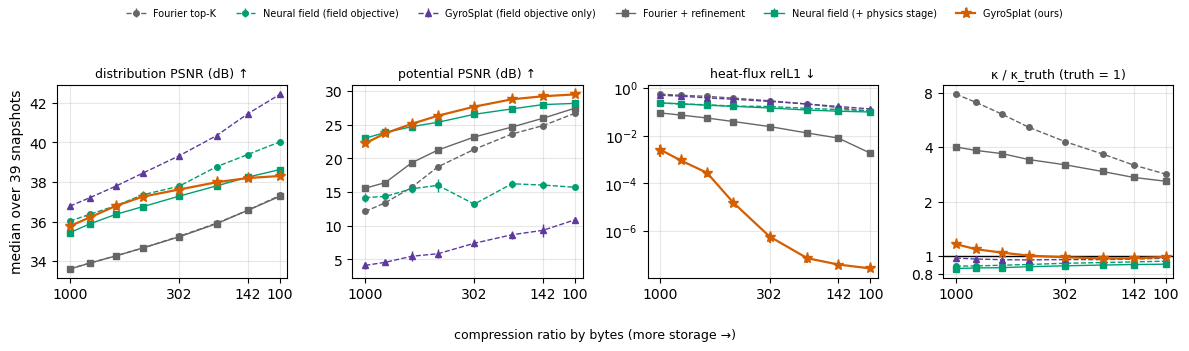

In [6]:
fig = rd_figure(exp)
fig.savefig(FIGURES / "rate_distortion.pdf", bbox_inches="tight")
plt.show()

## 5. Table 3: the physics refinement on other codes

The same objective on other codes at the same bytes: 400 Adam steps on the field, potential and flux terms, then the Gauss-Newton refinement of the kept Fourier or Haar coefficients; for the AE, VAE and VQ-VAE the 400 Adam steps move the stored latent through the frozen decoder (302× only; the appendix notebook `04_frozen_decoders` has the Gauss-Newton and Levenberg-Marquardt variants). Below it, the db4 wavelet at the two byte budgets (Table 4).

In [7]:
display(Markdown(X.refinement_table(exp, rows)))
display(Markdown(X.db4_table(exp)))

| representation | PSNR_f ↑ | PSNR_φ ↑ | flux relL1 ↓ | κ/κ_truth |
|---|---|---|---|---|
| *CR ≈ 302×* | | | | |
| Haar + refinement | 12.90 | -15.08 | 1.8×10⁻⁷ | 15.814 |
| Fourier + refinement | 35.23 | 23.19 | 0.024 | 3.194 |
| AE + refinement | 35.88 | 26.57 | 0.032 | 0.857 |
| VAE + refinement | 34.75 | 24.18 | 0.063 | 0.816 |
| VQ-VAE + refinement | 34.50 | 22.97 | 0.087 | 0.793 |
| GyroSplat | 37.63 | 27.69 | 5.2×10⁻⁷ | 0.984 |
| *CR ≈ 142×* | | | | |
| Haar + refinement | 22.82 | -11.42 | 8.5×10⁻⁸ | 4.419 |
| Fourier + refinement | 36.57 | 25.98 | 0.008 | 2.719 |
| GyroSplat | 38.21 | 29.24 | 3.7×10⁻⁸ | 0.973 |

| basis | CR | PSNR_f | PSNR_φ | flux relL1 | κ/κ_truth |
|---|---|---|---|---|---|
| db4 | 302× | 34.67 | -13.45 | 1.0781 | 18.050 |
| db4 | 142× | 36.60 | -12.08 | 1.1530 | 11.160 |

## 6. Figures of single fits

Distribution PSNR against flux error at 302×, one point per snapshot (the seed-0 fit of the seeded methods, the byte-matched runs of the Fourier and Haar codes), the diamonds marking the medians of the plotted points; and the heat-flux spectrum of the snapshot with the largest flux error after the joint fit (`iteration_280_t25`).

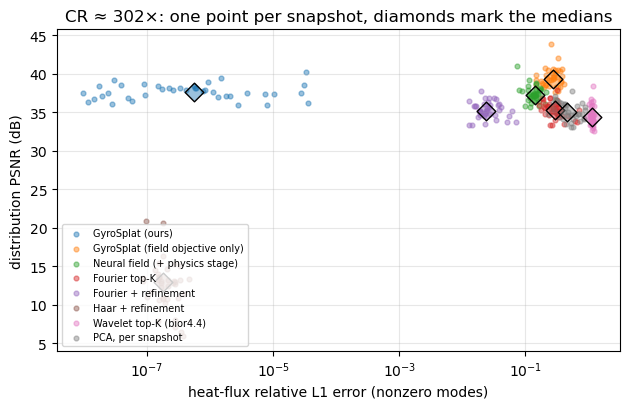

In [8]:
single = X.comparison_rows(exp, rows, seed=0)
fig = scatter_figure(single, 302, methods=("gyrosplat", "splats", "neural_field_physics", "fourier", "fourier_objective",
                                           "wavelet_haar_objective", "wavelet_bior4.4", "pca"))
fig.savefig(FIGURES / "scatter_302x.pdf", bbox_inches="tight")
plt.show()

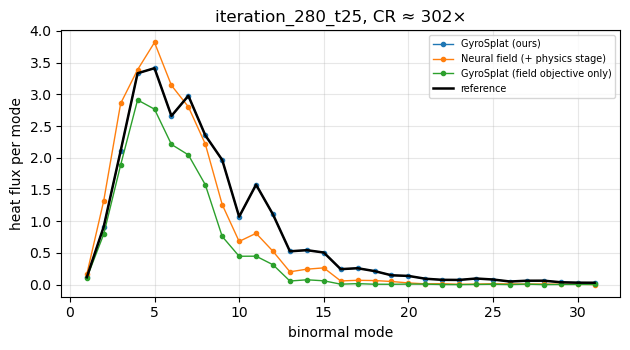

In [9]:
fig = flux_spectrum_figure(rows, "iteration_280_t25", 302, methods=("gyrosplat", "neural_field_physics", "splats"))
fig.savefig(FIGURES / "flux_spectrum_iteration_280_t25.pdf", bbox_inches="tight")
plt.show()

## 7. Rows regenerated with this package

The reproduction scripts write one JSON per method (or control), budget and snapshot:

```bash
scripts/gyrosplat/reproduce_gkw.sh <data_root> neugk/gyrosplat/results/package_runs
scripts/gyrosplat/reproduce_ablation.sh <data_root> neugk/gyrosplat/results/package_runs
```

`package_rows` converts those files into the row format, so they drop into the tables of this notebook. Below: the medians of the stored rows and of the re-run, over the snapshots the re-run covers (empty until a re-run exists). The experiments of the appendix were run with the scripts under `experiments/`.

In [10]:
runs = package_rows(sorted(glob.glob(str(RESULTS / "package_runs/*.json"))))
print(f"{len(runs)} rows from {len({r['snapshot'] for r in runs})} snapshots")
if runs:
    for tier in (302, 142):
        display(Markdown(compare_table(rows, runs, tier, ["gyrosplat", "splats", "fourier", "fourier_objective", "wavelet_haar",
                                                          "wavelet_haar_objective", "wavelet_db4", "wavelet_db8", "wavelet_bior4.4",
                                                          "pca", "zfp", "sz3", "neural_field"])))

0 rows from 0 snapshots


## 8. LaTeX

Every table has a `latex=True` form (a `tabular` with booktabs rules and the paper's macros).

In [11]:
print(X.main_table(exp, rows, latex=True, cite=True))
print()
print(ladder_table(rows, latex=True))

\begin{tabular}{lrrrr}
\toprule
method & PSNR$_f$\,\up & PSNR$_\phi$\,\up & flux relL1\,\down & $\krel$ \\
\midrule
\multicolumn{5}{l}{\textit{CR $\approx 302\times$ (294{,}928 bytes)}}\\
Wavelet top-$K$ (bior4.4)~\citep{cohen1992biorthogonal} & $34.40$ & $-12.87$ & $1.1428$ & $12.487$ \\
Wavelet top-$K$ (Haar)~\citep{daubechies1992} & $34.40$ & $-8.32$ & $1.0094$ & $5.627$ \\
PCA, per snapshot~\citep{eckart1936approximation} & $35.08$ & $-2.54$ & $0.4551$ & $1.102$ \\
ZFP~\citep{lindstrom2014zfp} & $32.72$ & $-5.61$ & $0.9794$ & $18.972$ \\
SZ3~\citep{liang2022sz3} & $33.45$ & $-15.87$ & $1.2873$ & $19.873$ \\
Fourier top-$K$~\citep{devore1998nonlinear} & $35.25$ & $21.36$ & $0.2894$ & $4.290$ \\
Autoencoder~\citep{pinc2026} & $35.49$ & $15.42$ & $0.1308$ & $0.864$ \\
VAE~\citep{pinc2026} & $34.35$ & $9.33$ & $0.1925$ & $0.819$ \\
VQ-VAE~\citep{oord2018vqvae,pinc2026} & $34.16$ & $12.91$ & $0.2176$ & $0.793$ \\
Neural field (field objective)~\citep{pinc2026} & $37.37$ & $14.36$ & $0.1